# Lab Problem 4 : Logistic GLM vs. Least Squares in the Presence of a Spatial Outlier

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

In [2]:
n_per_class = 25
spread = 1.0  # std dev of each Gaussian cluster

# Class 0: 25 samples centered at (2, 2)
X0 = np.random.randn(n_per_class, 2) * spread + np.array([2, 2])
t0 = np.zeros(n_per_class)

# Class 1: 25 samples centered at (-2, -2)
X1 = np.random.randn(n_per_class, 2) * spread + np.array([-2, -2])
t1 = np.ones(n_per_class)

print("X0 shape:", X0.shape, " X1 shape:", X1.shape)

X0 shape: (25, 2)  X1 shape: (25, 2)


In [3]:
X_outlier = np.array([[35.0, 35.0]])
t_outlier = np.array([0.0])          # belongs to Class 0

X = np.vstack([X0, X1, X_outlier])   # (51, 2)
t = np.concatenate([t0, t1, t_outlier])  # (51,)

outlier_idx = X.shape[0] - 1         # index of the outlier = 50

print("Total observations:", X.shape[0])
print("Class 0 count:", int((t == 0).sum()), "| Class 1 count:", int((t == 1).sum()))

Total observations: 51
Class 0 count: 26 | Class 1 count: 25


In [4]:
def augment(X):
    """Prepend a bias column of ones: x = [x1, x2] -> phi = [1, x1, x2]."""
    return np.hstack([np.ones((X.shape[0], 1)), X])

Phi = augment(X)   # (51, 3) design matrix

print("Design matrix shape:", Phi.shape)
print("First 3 rows of Phi:\n", Phi[:3])
print("Outlier row of Phi:", Phi[outlier_idx])

Design matrix shape: (51, 3)
First 3 rows of Phi:
 [[1.         2.49671415 1.8617357 ]
 [1.         2.64768854 3.52302986]
 [1.         1.76584663 1.76586304]]
Outlier row of Phi: [ 1. 35. 35.]


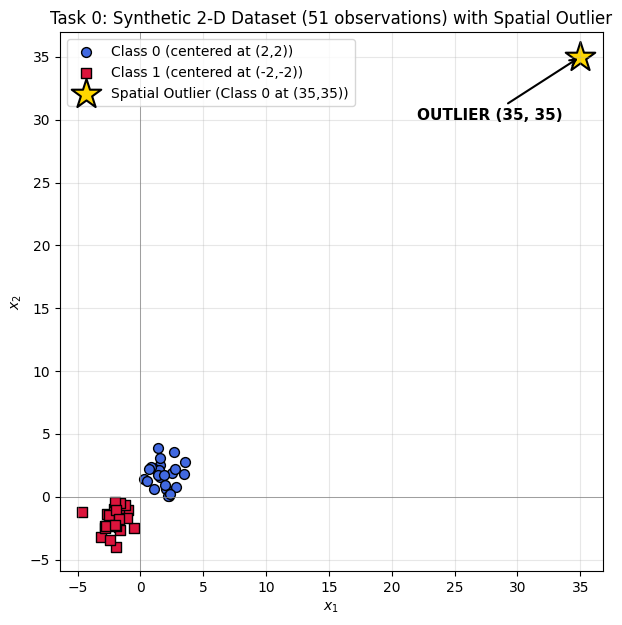

In [5]:
plt.figure(figsize=(7, 7))

plt.scatter(X0[:, 0], X0[:, 1], c='royalblue', marker='o', s=50,
            edgecolors='k', label='Class 0 (centered at (2,2))')
plt.scatter(X1[:, 0], X1[:, 1], c='crimson', marker='s', s=50,
            edgecolors='k', label='Class 1 (centered at (-2,-2))')
plt.scatter(X_outlier[:, 0], X_outlier[:, 1], c='gold', marker='*', s=500,
            edgecolors='k', linewidths=1.5, label='Spatial Outlier (Class 0 at (35,35))')

plt.annotate('OUTLIER (35, 35)', xy=(35, 35), xytext=(22, 30),
             arrowprops=dict(arrowstyle='->', lw=1.5, color='black'),
             fontsize=11, fontweight='bold')

plt.axhline(0, color='gray', lw=0.5)
plt.axvline(0, color='gray', lw=0.5)
plt.xlabel('$x_1$'); plt.ylabel('$x_2$')
plt.title('Task 0: Synthetic 2-D Dataset (51 observations) with Spatial Outlier')
plt.legend(loc='upper left'); plt.grid(alpha=0.3)
plt.axis('equal')
plt.show()


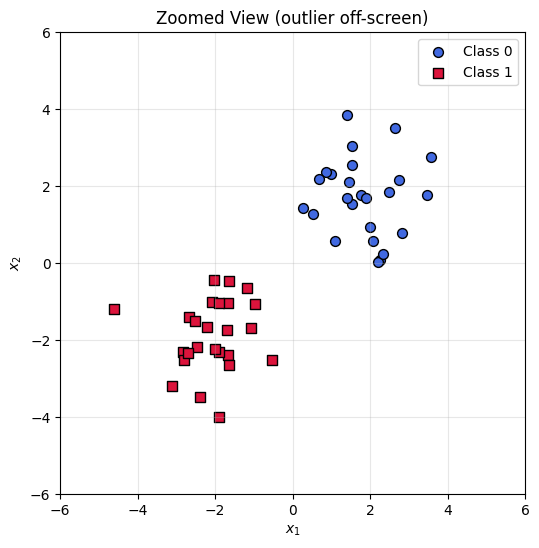

In [6]:
plt.figure(figsize=(6, 6))
plt.scatter(X0[:, 0], X0[:, 1], c='royalblue', marker='o', s=50, edgecolors='k', label='Class 0')
plt.scatter(X1[:, 0], X1[:, 1], c='crimson', marker='s', s=50, edgecolors='k', label='Class 1')
plt.xlim(-6, 6); plt.ylim(-6, 6)
plt.xlabel('$x_1$'); plt.ylabel('$x_2$')
plt.title('Zoomed View (outlier off-screen)')
plt.legend(); plt.grid(alpha=0.3)
plt.show()


Task 1 — Bernoulli GLM (Logistic Regression) via Gradient Descent

In [7]:
def linear_predictor(Phi, w):
    """a_n = w^T phi_n"""
    return Phi @ w

def sigmoid(a):
    """Numerically stable logistic sigmoid: y = 1 / (1 + exp(-a))"""
    out = np.empty_like(a, dtype=float)
    pos = a >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-a[pos]))
    ea = np.exp(a[~pos])
    out[~pos] = ea / (1.0 + ea)
    return out

def bernoulli_nll(t, y, eps=1e-12):
    """L(w) = -sum_n [ t_n log(y_n) + (1 - t_n) log(1 - y_n) ]"""
    y = np.clip(y, eps, 1 - eps)
    return -np.sum(t * np.log(y) + (1 - t) * np.log(1 - y))

In [8]:
def train_logistic_glm(Phi, t, eta=0.1, n_iter=1000, w_init=None, verbose_every=100):
    """
    Batch gradient descent on the Bernoulli NLL.
    Update rule: w_new = w_old - eta * sum_n (y_n - t_n) * phi_n
    """
    w = np.zeros(Phi.shape[1]) if w_init is None else w_init.astype(float).copy()
    loss_history, w_history = [], [w.copy()]

    for it in range(n_iter):
        a = linear_predictor(Phi, w)
        y = sigmoid(a)
        grad = Phi.T @ (y - t)        # sum_n (y_n - t_n) phi_n
        w = w - eta * grad

        loss = bernoulli_nll(t, sigmoid(Phi @ w))
        loss_history.append(loss)
        w_history.append(w.copy())

        if verbose_every and (it + 1) % verbose_every == 0:
            print(f"iter {it+1:4d} | NLL = {loss:12.6f} | w = {np.round(w, 4)}")

    return w, np.array(loss_history), np.array(w_history)

In [9]:
eta = 0.1
n_iter = 1000

w_glm, loss_hist, w_hist = train_logistic_glm(Phi, t, eta=eta, n_iter=n_iter)

print("\nFinal weights (w0, w1, w2):", w_glm)
print("Final NLL:", loss_hist[-1])

iter  100 | NLL =     0.000057 | w = [-0.0504 -6.6401 -6.2527]
iter  200 | NLL =     0.000057 | w = [-0.0507 -6.6406 -6.2533]
iter  300 | NLL =     0.000057 | w = [-0.0511 -6.641  -6.2539]
iter  400 | NLL =     0.000057 | w = [-0.0514 -6.6414 -6.2545]
iter  500 | NLL =     0.000057 | w = [-0.0518 -6.6419 -6.255 ]
iter  600 | NLL =     0.000057 | w = [-0.0522 -6.6423 -6.2556]
iter  700 | NLL =     0.000057 | w = [-0.0525 -6.6427 -6.2562]
iter  800 | NLL =     0.000057 | w = [-0.0529 -6.6431 -6.2568]
iter  900 | NLL =     0.000057 | w = [-0.0532 -6.6436 -6.2573]
iter 1000 | NLL =     0.000057 | w = [-0.0536 -6.644  -6.2579]

Final weights (w0, w1, w2): [-0.05360546 -6.64398293 -6.25789722]
Final NLL: 5.6604226515200235e-05


In [10]:
N = Phi.shape[0]
w_glm_stable, loss_hist_s, w_hist_s = train_logistic_glm(
    Phi, t, eta=eta / N, n_iter=n_iter, verbose_every=200
)

print("\nFinal weights (stabilized):", w_glm_stable)
print("Final NLL:", loss_hist_s[-1])

iter  200 | NLL =     0.790773 | w = [-0.0862 -1.5106 -1.3068]
iter  400 | NLL =     0.439639 | w = [-0.1158 -1.7884 -1.5422]
iter  600 | NLL =     0.310372 | w = [-0.1351 -1.9574 -1.6878]
iter  800 | NLL =     0.241904 | w = [-0.1497 -2.0801 -1.7948]
iter 1000 | NLL =     0.199127 | w = [-0.1615 -2.1768 -1.8799]

Final weights (stabilized): [-0.16150392 -2.17680476 -1.87985587]
Final NLL: 0.1991271148229437


In [11]:
def predict_proba(Phi, w):
    return sigmoid(Phi @ w)

def predict_label(Phi, w, threshold=0.5):
    return (predict_proba(Phi, w) >= threshold).astype(float)

def accuracy(t, t_pred):
    return np.mean(t == t_pred)

for name, w_ in [("GLM (eta=0.1, summed grad)", w_glm),
                 ("GLM (eta=0.1/N, stabilized)", w_glm_stable)]:
    t_pred = predict_label(Phi, w_)
    print(f"{name}")
    print(f"   weights  : w0={w_[0]:.4f}, w1={w_[1]:.4f}, w2={w_[2]:.4f}")
    print(f"   accuracy : {accuracy(t, t_pred)*100:.2f}%  "
          f"({int((t == t_pred).sum())}/{len(t)} correct)")
    print(f"   outlier  : true={t[outlier_idx]:.0f}, pred={t_pred[outlier_idx]:.0f}, "
          f"p(C1)={predict_proba(Phi, w_)[outlier_idx]:.4f}\n")

GLM (eta=0.1, summed grad)
   weights  : w0=-0.0536, w1=-6.6440, w2=-6.2579
   accuracy : 100.00%  (51/51 correct)
   outlier  : true=0, pred=0, p(C1)=0.0000

GLM (eta=0.1/N, stabilized)
   weights  : w0=-0.1615, w1=-2.1768, w2=-1.8799
   accuracy : 100.00%  (51/51 correct)
   outlier  : true=0, pred=0, p(C1)=0.0000



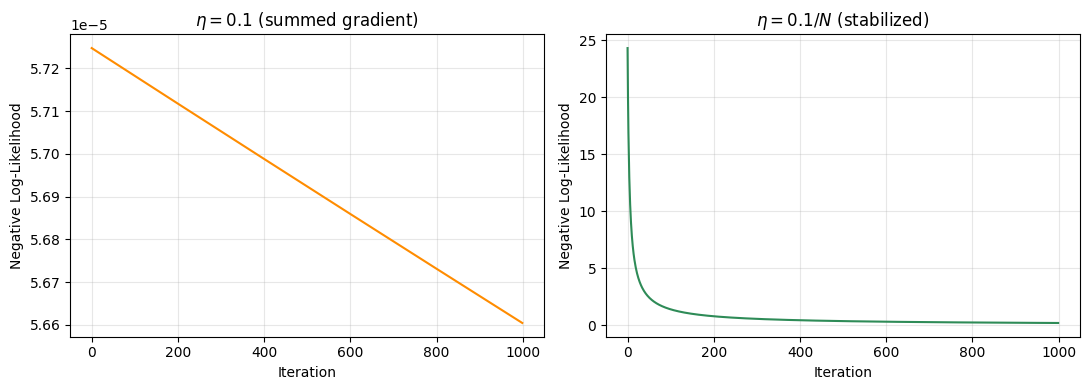

In [12]:
plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.plot(loss_hist, color='darkorange')
plt.xlabel('Iteration'); plt.ylabel('Negative Log-Likelihood')
plt.title(r'$\eta = 0.1$ (summed gradient)'); plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(loss_hist_s, color='seagreen')
plt.xlabel('Iteration'); plt.ylabel('Negative Log-Likelihood')
plt.title(r'$\eta = 0.1/N$ (stabilized)'); plt.grid(alpha=0.3)

plt.tight_layout(); plt.show()


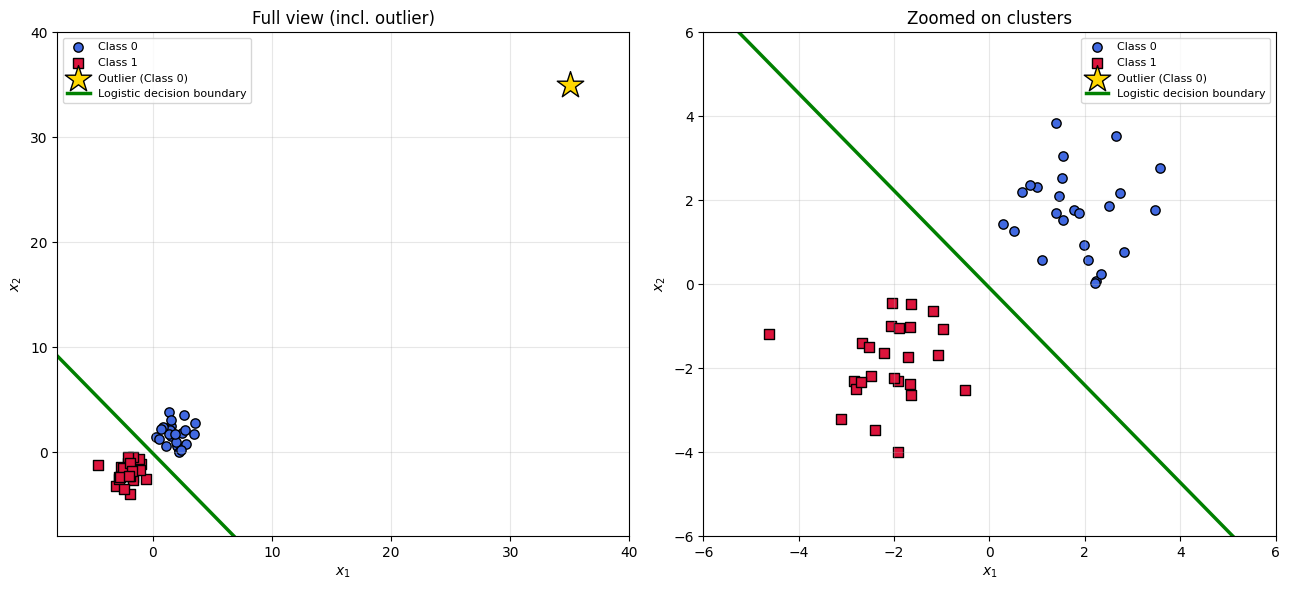

In [13]:
def boundary_line(w, x1_vals):
    """Solve w0 + w1*x1 + w2*x2 = 0  ->  x2 = -(w0 + w1*x1)/w2"""
    if np.isclose(w[2], 0):
        return None
    return -(w[0] + w[1] * x1_vals) / w[2]

def plot_with_boundary(w, title, xlim, ylim, color='green'):
    x1_vals = np.linspace(xlim[0], xlim[1], 200)
    x2_vals = boundary_line(w, x1_vals)

    plt.scatter(X0[:, 0], X0[:, 1], c='royalblue', marker='o', s=45,
                edgecolors='k', label='Class 0')
    plt.scatter(X1[:, 0], X1[:, 1], c='crimson', marker='s', s=45,
                edgecolors='k', label='Class 1')
    plt.scatter(X_outlier[:, 0], X_outlier[:, 1], c='gold', marker='*', s=400,
                edgecolors='k', label='Outlier (Class 0)')
    if x2_vals is not None:
        plt.plot(x1_vals, x2_vals, color=color, lw=2.5, label='Logistic decision boundary')
    plt.xlim(xlim); plt.ylim(ylim)
    plt.xlabel('$x_1$'); plt.ylabel('$x_2$'); plt.title(title)
    plt.legend(loc='best', fontsize=8); plt.grid(alpha=0.3)

plt.figure(figsize=(13, 6))
plt.subplot(1, 2, 1)
plot_with_boundary(w_glm_stable, 'Full view (incl. outlier)', (-8, 40), (-8, 40))
plt.subplot(1, 2, 2)
plot_with_boundary(w_glm_stable, 'Zoomed on clusters', (-6, 6), (-6, 6))
plt.tight_layout(); plt.show()


In [14]:
t_pred_glm = predict_label(Phi, w_glm_stable)

print("=" * 55)
print("TASK 1 RESULTS — Bernoulli GLM (Logistic Regression)")
print("=" * 55)
print(f"Learning rate      : {eta}  (applied as eta/N for stability)")
print(f"Iterations         : {n_iter}")
print(f"Initial weights    : [0, 0, 0]")
print(f"Final weights      : w0 = {w_glm_stable[0]:.4f}, "
      f"w1 = {w_glm_stable[1]:.4f}, w2 = {w_glm_stable[2]:.4f}")
print(f"Final NLL          : {loss_hist_s[-1]:.6f}")
print(f"Accuracy           : {accuracy(t, t_pred_glm)*100:.2f}%")
print(f"Misclassified idx  : {np.where(t != t_pred_glm)[0]}")
print(f"Boundary equation  : {w_glm_stable[0]:.4f} + {w_glm_stable[1]:.4f}*x1 "
      f"+ {w_glm_stable[2]:.4f}*x2 = 0")
print("=" * 55)

TASK 1 RESULTS — Bernoulli GLM (Logistic Regression)
Learning rate      : 0.1  (applied as eta/N for stability)
Iterations         : 1000
Initial weights    : [0, 0, 0]
Final weights      : w0 = -0.1615, w1 = -2.1768, w2 = -1.8799
Final NLL          : 0.199127
Accuracy           : 100.00%
Misclassified idx  : []
Boundary equation  : -0.1615 + -2.1768*x1 + -1.8799*x2 = 0


Task 2 — Least Squares Linear Model

In [15]:
def train_least_squares(Phi, t):
    """
    Closed-form LS solution: w = (Phi^T Phi)^-1 Phi^T t
    Uses pinv for numerical stability (equivalent when Phi^T Phi is invertible).
    """
    PhiT_Phi = Phi.T @ Phi
    w = np.linalg.inv(PhiT_Phi) @ Phi.T @ t
    return w

w_ls = train_least_squares(Phi, t)
print("Final LS weights (w0, w1, w2):", w_ls)

Final LS weights (w0, w1, w2): [ 0.51397161 -0.06620199  0.02087375]


In [16]:
def ls_loss(t, y_pred):
    """L_LS(w) = sum_n (y_n - t_n)^2"""
    return np.sum((y_pred - t) ** 2)

def predict_label_ls(Phi, w, threshold=0.5):
    y_pred = Phi @ w
    return (y_pred >= threshold).astype(float), y_pred

t_pred_ls, y_pred_ls = predict_label_ls(Phi, w_ls, threshold=0.5)

print("LS loss (SSE)      :", ls_loss(t, y_pred_ls))
print("Accuracy            : {:.2f}%  ({}/{} correct)".format(
    accuracy(t, t_pred_ls) * 100, int((t == t_pred_ls).sum()), len(t)))
print(f"Outlier: true={t[outlier_idx]:.0f}, pred={t_pred_ls[outlier_idx]:.0f}, "
      f"raw score={y_pred_ls[outlier_idx]:.4f}")
print("Misclassified idx   :", np.where(t != t_pred_ls)[0])

LS loss (SSE)      : 9.666423791372488
Accuracy            : 88.24%  (45/51 correct)
Outlier: true=0, pred=0, raw score=-1.0725
Misclassified idx   : [ 7 13 15 19 22 41]


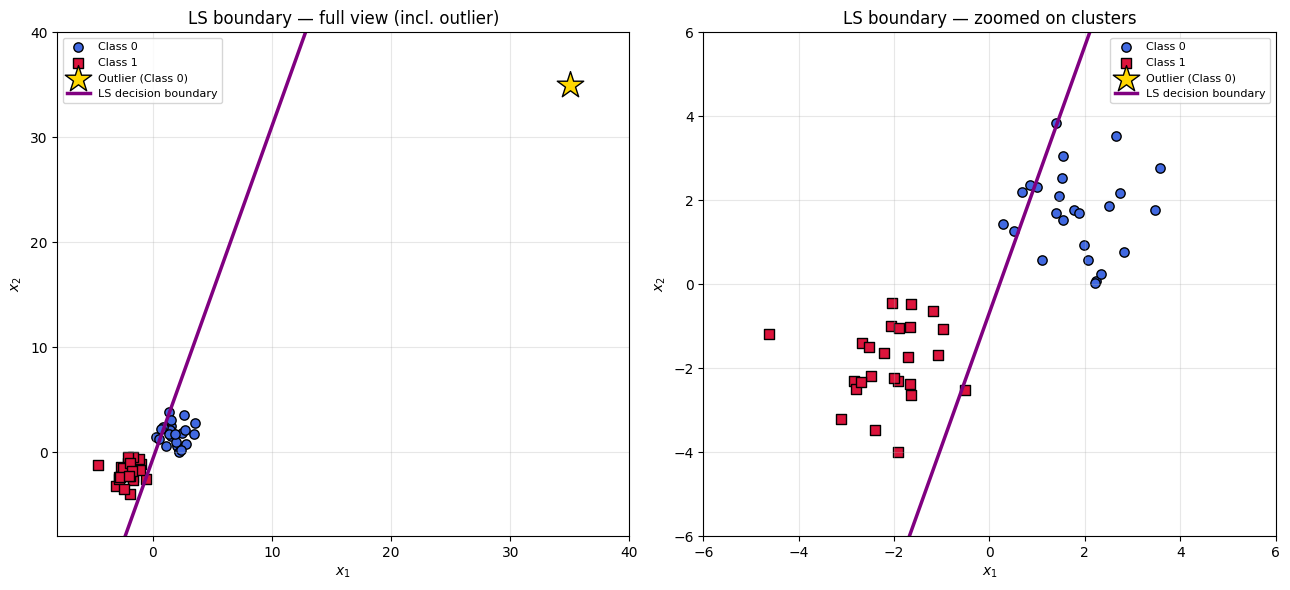

In [17]:
def boundary_line_ls(w, x1_vals, threshold=0.5):
    """Solve w0 + w1*x1 + w2*x2 = threshold -> x2 = (threshold - w0 - w1*x1)/w2"""
    if np.isclose(w[2], 0):
        return None
    return (threshold - w[0] - w[1] * x1_vals) / w[2]

def plot_ls_boundary(w, title, xlim, ylim, color='purple'):
    x1_vals = np.linspace(xlim[0], xlim[1], 200)
    x2_vals = boundary_line_ls(w, x1_vals)

    plt.scatter(X0[:, 0], X0[:, 1], c='royalblue', marker='o', s=45,
                edgecolors='k', label='Class 0')
    plt.scatter(X1[:, 0], X1[:, 1], c='crimson', marker='s', s=45,
                edgecolors='k', label='Class 1')
    plt.scatter(X_outlier[:, 0], X_outlier[:, 1], c='gold', marker='*', s=400,
                edgecolors='k', label='Outlier (Class 0)')
    if x2_vals is not None:
        plt.plot(x1_vals, x2_vals, color=color, lw=2.5, label='LS decision boundary')
    plt.xlim(xlim); plt.ylim(ylim)
    plt.xlabel('$x_1$'); plt.ylabel('$x_2$'); plt.title(title)
    plt.legend(loc='best', fontsize=8); plt.grid(alpha=0.3)

plt.figure(figsize=(13, 6))
plt.subplot(1, 2, 1)
plot_ls_boundary(w_ls, 'LS boundary — full view (incl. outlier)', (-8, 40), (-8, 40))
plt.subplot(1, 2, 2)
plot_ls_boundary(w_ls, 'LS boundary — zoomed on clusters', (-6, 6), (-6, 6))
plt.tight_layout(); plt.show()


In [18]:
print("=" * 55)
print("TASK 2 RESULTS — Least Squares Linear Model")
print("=" * 55)
print(f"Final weights      : w0 = {w_ls[0]:.4f}, "
      f"w1 = {w_ls[1]:.4f}, w2 = {w_ls[2]:.4f}")
print(f"LS loss (SSE)      : {ls_loss(t, y_pred_ls):.6f}")
print(f"Classification thr : 0.5")
print(f"Accuracy           : {accuracy(t, t_pred_ls)*100:.2f}%")
print(f"Misclassified idx  : {np.where(t != t_pred_ls)[0]}")
print(f"Boundary equation  : {w_ls[0]:.4f} + {w_ls[1]:.4f}*x1 "
      f"+ {w_ls[2]:.4f}*x2 = 0.5")
print("=" * 55)

TASK 2 RESULTS — Least Squares Linear Model
Final weights      : w0 = 0.5140, w1 = -0.0662, w2 = 0.0209
LS loss (SSE)      : 9.666424
Classification thr : 0.5
Accuracy           : 88.24%
Misclassified idx  : [ 7 13 15 19 22 41]
Boundary equation  : 0.5140 + -0.0662*x1 + 0.0209*x2 = 0.5


Task 3 — Model Comparison

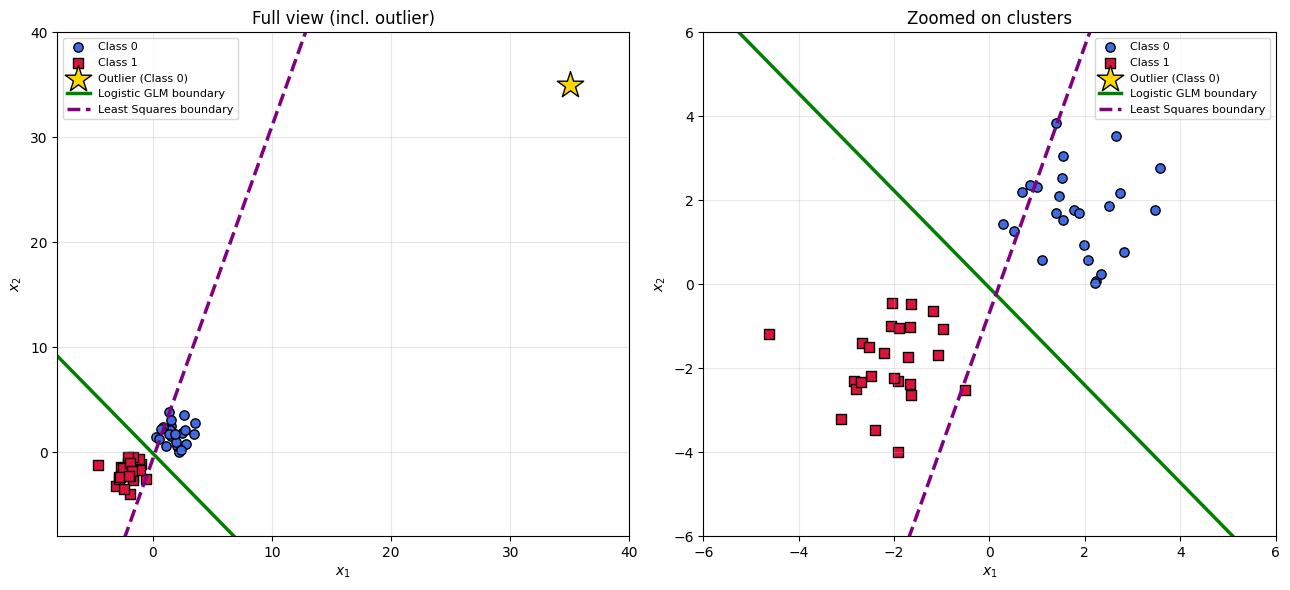

In [19]:
def plot_comparison(w_glm, w_ls, xlim, ylim, title):
    x1_vals = np.linspace(xlim[0], xlim[1], 200)
    x2_glm = boundary_line(w_glm, x1_vals)          # w0+w1x1+w2x2 = 0
    x2_ls  = boundary_line_ls(w_ls, x1_vals)         # w0+w1x1+w2x2 = 0.5

    plt.scatter(X0[:, 0], X0[:, 1], c='royalblue', marker='o', s=45,
                edgecolors='k', label='Class 0')
    plt.scatter(X1[:, 0], X1[:, 1], c='crimson', marker='s', s=45,
                edgecolors='k', label='Class 1')
    plt.scatter(X_outlier[:, 0], X_outlier[:, 1], c='gold', marker='*', s=400,
                edgecolors='k', label='Outlier (Class 0)')

    if x2_glm is not None:
        plt.plot(x1_vals, x2_glm, color='green', lw=2.5, label='Logistic GLM boundary')
    if x2_ls is not None:
        plt.plot(x1_vals, x2_ls, color='purple', lw=2.5, ls='--', label='Least Squares boundary')

    plt.xlim(xlim); plt.ylim(ylim)
    plt.xlabel('$x_1$'); plt.ylabel('$x_2$'); plt.title(title)
    plt.legend(loc='best', fontsize=8); plt.grid(alpha=0.3)

plt.figure(figsize=(13, 6))
plt.subplot(1, 2, 1)
plot_comparison(w_glm_stable, w_ls, (-8, 40), (-8, 40), 'Full view (incl. outlier)')
plt.subplot(1, 2, 2)
plot_comparison(w_glm_stable, w_ls, (-6, 6), (-6, 6), 'Zoomed on clusters')
plt.tight_layout(); plt.show()


In [20]:
import pandas as pd

acc_glm = accuracy(t, t_pred_glm)
acc_ls  = accuracy(t, t_pred_ls)

outlier_pred_glm = t_pred_glm[outlier_idx]
outlier_pred_ls  = t_pred_ls[outlier_idx]

outlier_score_glm = predict_proba(Phi, w_glm_stable)[outlier_idx]
outlier_score_ls  = y_pred_ls[outlier_idx]

comparison = pd.DataFrame({
    "Measure": ["w0", "w1", "w2",
                "Classification Accuracy",
                "Prediction for Outlier (35,35)",
                "Raw score at Outlier"],
    "Logistic GLM": [
        f"{w_glm_stable[0]:.4f}",
        f"{w_glm_stable[1]:.4f}",
        f"{w_glm_stable[2]:.4f}",
        f"{acc_glm*100:.2f}%",
        f"Class {int(outlier_pred_glm)}",
        f"p(C1) = {outlier_score_glm:.4f}"
    ],
    "Least Squares": [
        f"{w_ls[0]:.4f}",
        f"{w_ls[1]:.4f}",
        f"{w_ls[2]:.4f}",
        f"{acc_ls*100:.2f}%",
        f"Class {int(outlier_pred_ls)}",
        f"y = {outlier_score_ls:.4f}"
    ]
})

comparison

,Measure,Logistic GLM,Least Squares
0,w0,-0.1615,0.5140
1,w1,-2.1768,-0.0662
2,w2,-1.8799,0.0209
3,Classification Accuracy,100.00%,88.24%
4,"Prediction for Outlier (35,35)",Class 0,Class 0
5,Raw score at Outlier,p(C1) = 0.0000,y = -1.0725


In [21]:
print("=" * 65)
print("TASK 3 RESULTS — Logistic GLM vs Least Squares")
print("=" * 65)
print(comparison.to_string(index=False))
print("=" * 65)
print(f"\nTrue label of outlier: Class {int(t[outlier_idx])}")
print(f"Logistic GLM {'correctly' if outlier_pred_glm==t[outlier_idx] else 'incorrectly'} "
      f"classifies the outlier.")
print(f"Least Squares {'correctly' if outlier_pred_ls==t[outlier_idx] else 'incorrectly'} "
      f"classifies the outlier.")

TASK 3 RESULTS — Logistic GLM vs Least Squares
                       Measure   Logistic GLM Least Squares
                            w0        -0.1615        0.5140
                            w1        -2.1768       -0.0662
                            w2        -1.8799        0.0209
       Classification Accuracy        100.00%        88.24%
Prediction for Outlier (35,35)        Class 0       Class 0
          Raw score at Outlier p(C1) = 0.0000   y = -1.0725

True label of outlier: Class 0
Logistic GLM correctly classifies the outlier.
Least Squares correctly classifies the outlier.


In [22]:
w_ls_no_outlier = train_least_squares(Phi[:-1], t[:-1])
w_glm_no_outlier, _, _ = train_logistic_glm(Phi[:-1], t[:-1], eta=eta/(N-1), n_iter=n_iter, verbose_every=0)

print("LS weights  with outlier   :", np.round(w_ls, 4))
print("LS weights  without outlier:", np.round(w_ls_no_outlier, 4))
print()
print("GLM weights with outlier   :", np.round(w_glm_stable, 4))
print("GLM weights without outlier:", np.round(w_glm_no_outlier, 4))
print()
print("=> Least Squares weights shift noticeably when the outlier is removed,")
print("   while the Logistic GLM weights are comparatively more stable —")
print("   illustrating the sigmoid's squashing effect vs. the LS quadratic penalty")
print("   on points far from the decision boundary.")

LS weights  with outlier   : [ 0.514  -0.0662  0.0209]
LS weights  without outlier: [ 0.4739 -0.1414 -0.0961]

GLM weights with outlier   : [-0.1615 -2.1768 -1.8799]
GLM weights without outlier: [-0.1624 -2.1858 -1.8867]

=> Least Squares weights shift noticeably when the outlier is removed,
   while the Logistic GLM weights are comparatively more stable —
   illustrating the sigmoid's squashing effect vs. the LS quadratic penalty
   on points far from the decision boundary.


Task 4 — Effect of the Spatial Outlier

In [23]:
Phi_no = Phi[:-1]      # first 50 rows (drop the outlier row)
t_no   = t[:-1]
X_no   = X[:-1]

print("Dataset without outlier:", Phi_no.shape[0], "observations")
print("Class 0 count:", int((t_no == 0).sum()), "| Class 1 count:", int((t_no == 1).sum()))

Dataset without outlier: 50 observations
Class 0 count: 25 | Class 1 count: 25


In [24]:
N_no = Phi_no.shape[0]
w_glm_no, loss_hist_no, _ = train_logistic_glm(
    Phi_no, t_no, eta=eta / N_no, n_iter=n_iter, verbose_every=200
)

t_pred_glm_no = predict_label(Phi_no, w_glm_no)
acc_glm_no = accuracy(t_no, t_pred_glm_no)

print("\nGLM weights (no outlier):", np.round(w_glm_no, 4))
print("GLM accuracy (no outlier): {:.2f}%".format(acc_glm_no * 100))

iter  200 | NLL =     0.779004 | w = [-0.0866 -1.5183 -1.3118]
iter  400 | NLL =     0.432628 | w = [-0.1164 -1.7968 -1.548 ]
iter  600 | NLL =     0.305289 | w = [-0.1359 -1.9662 -1.6941]
iter  800 | NLL =     0.237881 | w = [-0.1505 -2.089  -1.8014]
iter 1000 | NLL =     0.195780 | w = [-0.1624 -2.1858 -1.8867]

GLM weights (no outlier): [-0.1624 -2.1858 -1.8867]
GLM accuracy (no outlier): 100.00%


In [25]:
w_ls_no = train_least_squares(Phi_no, t_no)
t_pred_ls_no, y_pred_ls_no = predict_label_ls(Phi_no, w_ls_no, threshold=0.5)
acc_ls_no = accuracy(t_no, t_pred_ls_no)

print("LS weights (no outlier):", np.round(w_ls_no, 4))
print("LS accuracy (no outlier): {:.2f}%".format(acc_ls_no * 100))

LS weights (no outlier): [ 0.4739 -0.1414 -0.0961]
LS accuracy (no outlier): 100.00%


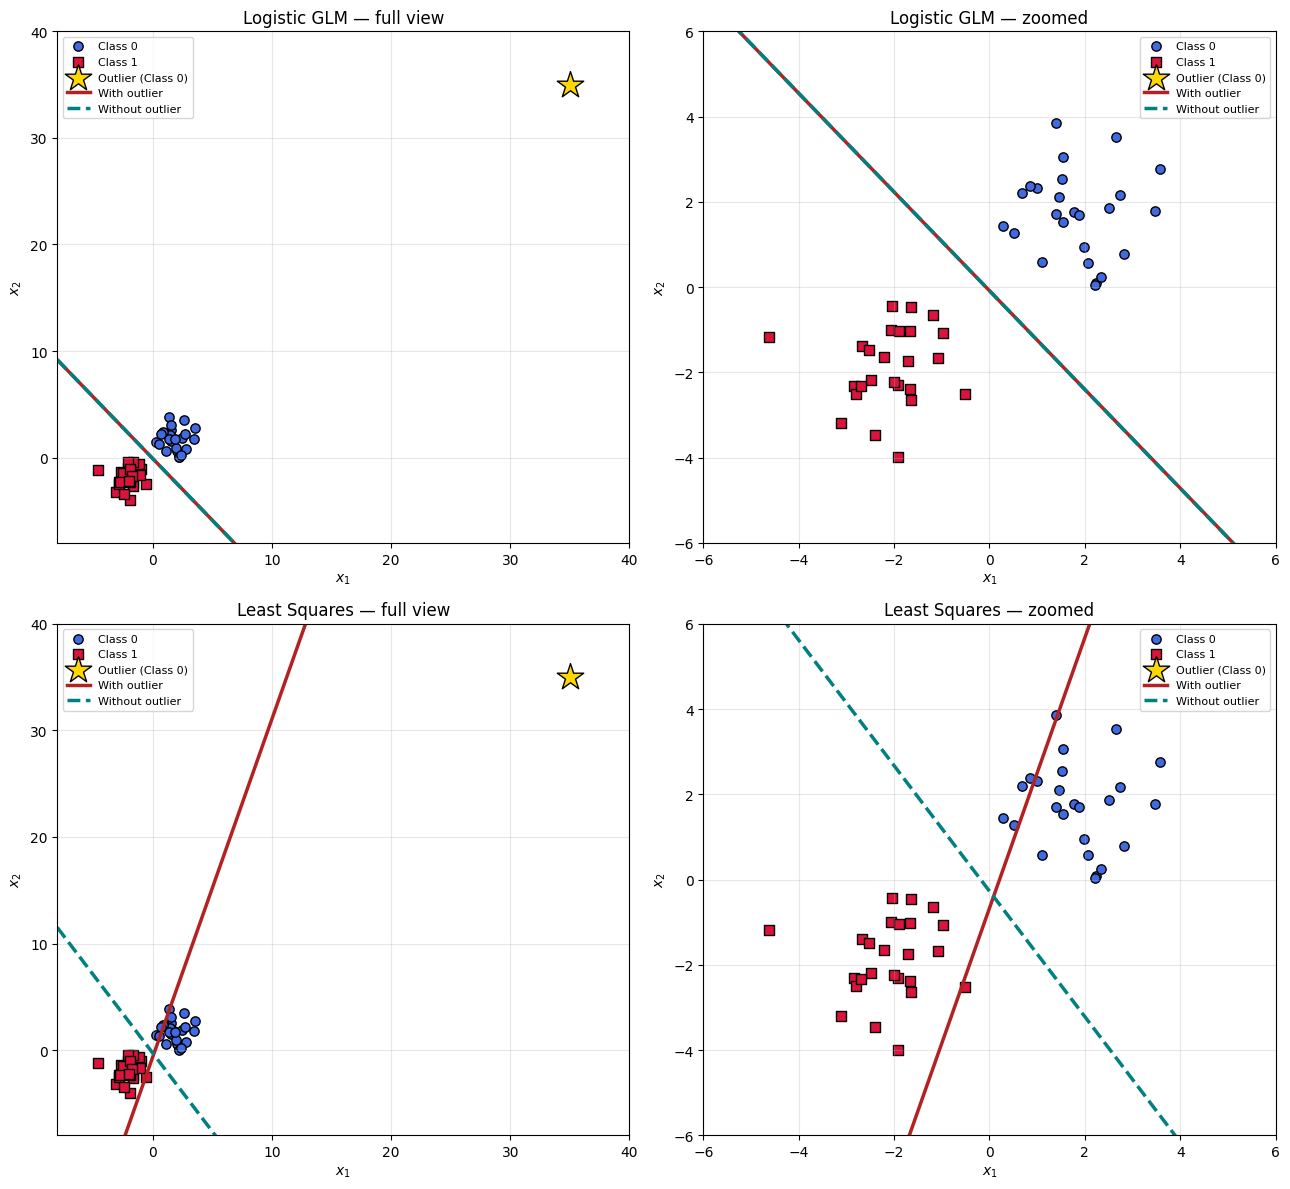

In [26]:
def plot_with_vs_without(w_with, w_no, kind, xlim, ylim, title):
    x1_vals = np.linspace(xlim[0], xlim[1], 200)
    if kind == "glm":
        x2_with = boundary_line(w_with, x1_vals)
        x2_no   = boundary_line(w_no, x1_vals)
    else:
        x2_with = boundary_line_ls(w_with, x1_vals)
        x2_no   = boundary_line_ls(w_no, x1_vals)

    plt.scatter(X0[:, 0], X0[:, 1], c='royalblue', marker='o', s=45, edgecolors='k', label='Class 0')
    plt.scatter(X1[:, 0], X1[:, 1], c='crimson', marker='s', s=45, edgecolors='k', label='Class 1')
    plt.scatter(X_outlier[:, 0], X_outlier[:, 1], c='gold', marker='*', s=400,
                edgecolors='k', label='Outlier (Class 0)')

    if x2_with is not None:
        plt.plot(x1_vals, x2_with, color='firebrick', lw=2.5, label='With outlier')
    if x2_no is not None:
        plt.plot(x1_vals, x2_no, color='teal', lw=2.5, ls='--', label='Without outlier')

    plt.xlim(xlim); plt.ylim(ylim)
    plt.xlabel('$x_1$'); plt.ylabel('$x_2$'); plt.title(title)
    plt.legend(loc='best', fontsize=8); plt.grid(alpha=0.3)

plt.figure(figsize=(13, 12))

plt.subplot(2, 2, 1)
plot_with_vs_without(w_glm_stable, w_glm_no, "glm", (-8, 40), (-8, 40), 'Logistic GLM — full view')
plt.subplot(2, 2, 2)
plot_with_vs_without(w_glm_stable, w_glm_no, "glm", (-6, 6), (-6, 6), 'Logistic GLM — zoomed')

plt.subplot(2, 2, 3)
plot_with_vs_without(w_ls, w_ls_no, "ls", (-8, 40), (-8, 40), 'Least Squares — full view')
plt.subplot(2, 2, 4)
plot_with_vs_without(w_ls, w_ls_no, "ls", (-6, 6), (-6, 6), 'Least Squares — zoomed')

plt.tight_layout(); plt.show()


In [27]:
delta_w_glm = w_glm_stable - w_glm_no
delta_w_ls  = w_ls - w_ls_no

print("Δw (GLM)  = w_with - w_without :", np.round(delta_w_glm, 4))
print("Δw (LS)   = w_with - w_without :", np.round(delta_w_ls, 4))

print("\n||Δw||_2  GLM :", np.linalg.norm(delta_w_glm))
print("||Δw||_2  LS  :", np.linalg.norm(delta_w_ls))

Δw (GLM)  = w_with - w_without : [0.0009 0.009  0.0068]
Δw (LS)   = w_with - w_without : [0.0401 0.0752 0.1169]

||Δw||_2  GLM : 0.011367509654273153
||Δw||_2  LS  : 0.14470059648987466


In [28]:
outlier_true = t[outlier_idx]

table = pd.DataFrame({
    "Measure": ["w0", "w1", "w2", "Δw0", "Δw1", "Δw2", "||Δw||_2",
                "Accuracy (on its own dataset)", "Outlier true class"],
    "GLM - With Outlier": [
        f"{w_glm_stable[0]:.4f}", f"{w_glm_stable[1]:.4f}", f"{w_glm_stable[2]:.4f}",
        f"{delta_w_glm[0]:.4f}", f"{delta_w_glm[1]:.4f}", f"{delta_w_glm[2]:.4f}",
        f"{np.linalg.norm(delta_w_glm):.4f}",
        f"{acc_glm*100:.2f}%", f"{int(outlier_true)}"
    ],
    "GLM - Without Outlier": [
        f"{w_glm_no[0]:.4f}", f"{w_glm_no[1]:.4f}", f"{w_glm_no[2]:.4f}",
        "—", "—", "—", "—",
        f"{acc_glm_no*100:.2f}%", "—"
    ],
    "LS - With Outlier": [
        f"{w_ls[0]:.4f}", f"{w_ls[1]:.4f}", f"{w_ls[2]:.4f}",
        f"{delta_w_ls[0]:.4f}", f"{delta_w_ls[1]:.4f}", f"{delta_w_ls[2]:.4f}",
        f"{np.linalg.norm(delta_w_ls):.4f}",
        f"{acc_ls*100:.2f}%", f"{int(outlier_true)}"
    ],
    "LS - Without Outlier": [
        f"{w_ls_no[0]:.4f}", f"{w_ls_no[1]:.4f}", f"{w_ls_no[2]:.4f}",
        "—", "—", "—", "—",
        f"{acc_ls_no*100:.2f}%", "—"
    ],
})

table

,Measure,GLM - With Outlier,GLM - Without Outlier,LS - With Outlier,LS - Without Outlier
0,w0,-0.1615,-0.1624,0.5140,0.4739
1,w1,-2.1768,-2.1858,-0.0662,-0.1414
2,w2,-1.8799,-1.8867,0.0209,-0.0961
3,Δw0,0.0009,—,0.0401,—
4,Δw1,0.0090,—,0.0752,—
5,Δw2,0.0068,—,0.1169,—
6,||Δw||_2,0.0114,—,0.1447,—
7,Accuracy (on its own dataset),100.00%,100.00%,88.24%,100.00%
8,Outlier true class,0,—,0,—


In [29]:
print("=" * 80)
print("TASK 4 RESULTS — Effect of the Spatial Outlier")
print("=" * 80)
print(table.to_string(index=False))
print("=" * 80)

print(f"\nGLM  ||Δw||_2 = {np.linalg.norm(delta_w_glm):.4f}")
print(f"LS   ||Δw||_2 = {np.linalg.norm(delta_w_ls):.4f}")

if np.linalg.norm(delta_w_ls) > np.linalg.norm(delta_w_glm):
    print("\n=> The Least Squares weight vector changes more when the outlier is removed,")
    print("   confirming it is more sensitive to the spatial outlier.")
    print("   The Logistic GLM's sigmoid saturates for large |a|, capping the")
    print("   gradient contribution of far-away points and yielding a more")
    print("   stable decision boundary.")
else:
    print("\n=> The Logistic GLM weight vector changes more when the outlier is removed.")

TASK 4 RESULTS — Effect of the Spatial Outlier
                      Measure GLM - With Outlier GLM - Without Outlier LS - With Outlier LS - Without Outlier
                           w0            -0.1615               -0.1624            0.5140               0.4739
                           w1            -2.1768               -2.1858           -0.0662              -0.1414
                           w2            -1.8799               -1.8867            0.0209              -0.0961
                          Δw0             0.0009                     —            0.0401                    —
                          Δw1             0.0090                     —            0.0752                    —
                          Δw2             0.0068                     —            0.1169                    —
                     ||Δw||_2             0.0114                     —            0.1447                    —
Accuracy (on its own dataset)            100.00%               100.00%   